<a href="https://colab.research.google.com/github/nlozano-data/NovaRetail---Analysis/blob/main/S8_Student_Version_Project_NovaRetail.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

In [ ]:
# Importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns# Importar librerías

### Cargar Dataset

In [ ]:

# Cargar el dataset y explorar datos
df = pd.read_csv('/datasets/novaretail_comportamiento_clientes_2024.csv')

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [ ]:

# Mostrar las primeras 5 filas
df.head()



,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
-

La mayoría de estas variables presentan tipos de datos adecuados.  
La columna ... .


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [ ]:

# Corregir el tipo de dato

# Verificar si todas las edades son números enteros
df['edad'].mod(1).eq(0).all()

# Convertir edad a entero
df['edad'] = df['edad'].astype(int)

In [ ]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [ ]:
# Estadísticas descriptivas de variables numéricas
df.describe()

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,0.139267,0.150733,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,0.346236,0.357801,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000,0.000000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,0.000000,0.000000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,0.000000,0.000000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,1.000000,1.000000,244.690000



**Diagnóstico inicial de variables numéricas**

- Edad: presenta un promedio de 38.26 años, con valores entre 18 y 75 años. La distribución muestra diversidad en las edades de los clientes y no presenta valores fuera del rango esperado.
- Nivel de ingreso: registra un promedio aproximado de 30,019, con valores entre 8,000 y 74,790.84. Existe una variabilidad considerable entre los niveles de ingreso de los clientes.
- Visitas_mes: presenta un promedio de 10.03 visitas mensuales, con un mínimo de 1 y un máximo de 25. Esto evidencia diferentes niveles de interacción con la plataforma.
- Compras_mes: registra un promedio de 1.21 compras mensuales, con valores entre 0 y 8. La mediana es de 1 compra, lo que indica que al menos la mitad de los clientes realiza una compra mensual o menos.
- Gasto_publicidad_dirigida: tiene un promedio de 20.15 y valores entre 0 y 75.51. Se identifican clientes sin gasto publicitario asignado y diferencias importantes en la inversión dirigida a los usuarios.
- Satisfacción: presenta un promedio de 3.61 sobre 5, con valores entre 1 y 5. En general, se observa una valoración superior al punto medio de la escala.
- Ingreso_anual: presenta un promedio de 36.59, una mediana de 30.71 y valores entre 0 y 244.69. La diferencia entre el promedio y la mediana sugiere una posible asimetría positiva y la presencia de clientes con ingresos considerablemente superiores al resto.

**Conclusión general:** Las variables presentan rangos y dispersiones diferentes. Se observan diferencias importantes en el comportamiento y el valor económico de los clientes. Será necesario profundizar mediante visualizaciones y análisis de correlación para identificar posibles relaciones y valores atípicos.


#### Explorar variables binarias

In [ ]:

# Verificar que cada columna tenga únicamente dos valores posibles

print("Valores de miembro_premium:")
print(df['miembro_premium'].unique())

print("\nValores de abandono:")
print(df['abandono'].unique())

Valores de miembro_premium:
[0 1]

Valores de abandono:
[0 1]


**Diagnóstico inicial de variables binarias**

- miembro_premium: variable binaria que identifica si el cliente cuenta con una suscripción premium. Sus valores son 0 y 1, por lo que presenta una codificación adecuada y no requiere transformación adicional.
- abandono: variable binaria que identifica si el cliente abandonó la plataforma. Sus valores son 0 y 1, por lo que presenta una codificación adecuada y no requiere transformación adicional.

Conclusión: Ambas variables presentan únicamente dos valores posibles (0 y 1), cumplen con su naturaleza binaria y están listas para el análisis.

#### Explorar variables categóricas

In [ ]:
# Verificar el número de valores únicos por variable categórica

print("Categorías de tipo_dispositivo:")
print(df['tipo_dispositivo'].nunique())

print("\nCategorías de region:")
print(df['region'].nunique())

Categorías de tipo_dispositivo:
3

Categorías de region:
4


In [ ]:
# Explorar variables categóricas y cómo se distribuyen

print("Distribución por tipo de dispositivo:")
print(df['tipo_dispositivo'].value_counts())

print("\nDistribución por región:")
print(df['region'].value_counts())

Distribución por tipo de dispositivo:
móvil         9818
escritorio    3720
tablet        1462
Name: tipo_dispositivo, dtype: int64

Distribución por región:
norte    4395
oeste    3810
sur      3726
este     3069
Name: region, dtype: int64



**Diagnóstico inicial de variables categóricas**

- tipo_dispositivo: presenta tres categorías: móvil, escritorio y tablet. El dispositivo móvil predomina con 9.818 clientes (65,5 %), seguido de escritorio con 3.720 (24,8 %) y tablet con 1.462 (9,7 %). Esto evidencia una mayor participación de usuarios que acceden a la plataforma mediante dispositivos móviles.
- region: presenta cuatro categorías: norte, sur, oeste y este. La región norte concentra 4.395 clientes (29,3 %), seguida de oeste con 3.810 (25,4 %), sur con 3.726 (24,8 %) y este con 3.069 (20,5 %). La distribución regional es relativamente equilibrada, aunque el norte presenta una mayor concentración de clientes.

Conclusión: Las variables categóricas presentan categorías identificables y distribuciones sin inconsistencias aparentes. No requieren transformaciones adicionales para el análisis de asociación mediante V de Cramér.

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones



### Heatmap

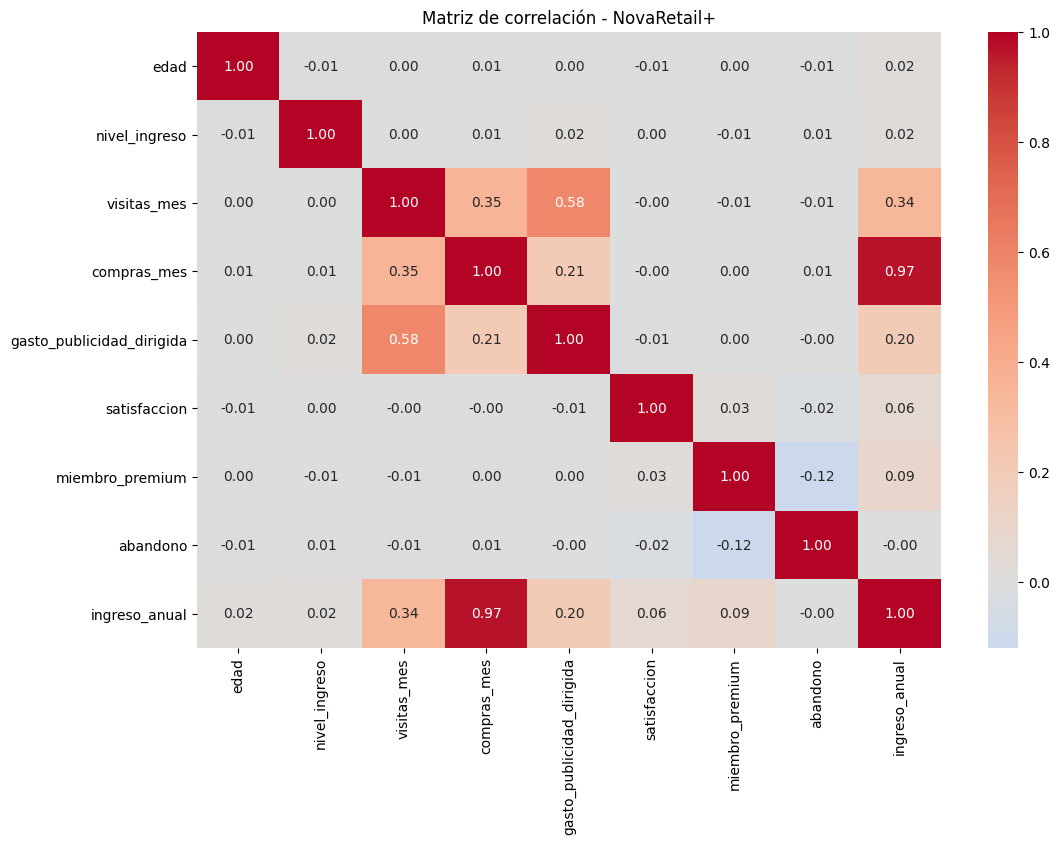

In [ ]:

# Visualizar la matriz de correlación para identificar relaciones

# Seleccionar variables numéricas
columnas_numericas = df.select_dtypes(include='number')

# Calcular matriz de correlación
matriz_corr = columnas_numericas.corr()

# Crear el gráfico
plt.figure(figsize=(12, 8))

sns.heatmap(
    matriz_corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.title('Matriz de correlación - NovaRetail+')
plt.show()

### Observaciones generales (Heatmap)

- Se observa una correlación positiva moderada entre visitas_mes y gasto_publicidad_dirigida (0.58), lo que indica que los clientes con mayor actividad de visitas tienden a presentar mayores niveles de gasto publicitario asignado.
- Existe una correlación positiva entre visitas_mes y compras_mes (0.35), así como entre visitas_mes e ingreso_anual (0.34).
- La relación entre compras_mes y gasto_publicidad_dirigida es positiva, pero débil (0.21).
- Se identifica una correlación negativa débil entre miembro_premium y abandono (-0.12).
- Las variables edad, nivel_ingreso y satisfaccion presentan correlaciones cercanas a cero con la mayoría de las demás variables.

### Observaciones respecto a ingreso_anual

- Presenta una correlación positiva muy fuerte con compras_mes (0.97), siendo esta la asociación más destacada del análisis.
- Presenta una correlación positiva moderada-débil con visitas_mes (0.34).
- Se observa una correlación positiva débil con gasto_publicidad_dirigida (0.20).
- Las asociaciones con miembro_premium (0.09), satisfaccion (0.06), nivel_ingreso (0.02) y edad (0.02) son muy débiles.
- La correlación con abandono es prácticamente nula (-0.00).

**Conclusión:** El número de compras mensuales es la variable que presenta la asociación lineal más fuerte con el ingreso anual generado por los clientes. Las visitas mensuales también muestran una relación positiva, aunque considerablemente menor. Estos resultados son exploratorios y no demuestran causalidad. La correlación de 0.97 entre compras_mes e ingreso_anual deberá examinarse con mayor profundidad para descartar una posible relación matemática directa o dependencia entre ambas variables.

### Scatterplot general

Con base en los resultados del análisis de correlación, evalúa si es necesario generar un *scatterplot* general.

- **No incluir scatterplot general**:

No se considera necesario generar un scatterplot general, debido a que el conjunto de datos contiene múltiples variables numéricas y su representación conjunta podría dificultar la interpretación de los patrones individuales.

En su lugar, se realizarán scatterplots para pares de variables seleccionadas a partir de los resultados del Heatmap, priorizando aquellas que presentan correlaciones moderadas o fuertes.

Esta decisión permite enfocar el análisis visual en las relaciones más relevantes para comprender el comportamiento de los clientes y su asociación con el ingreso anual generado.

### Scatterplot para pares clave

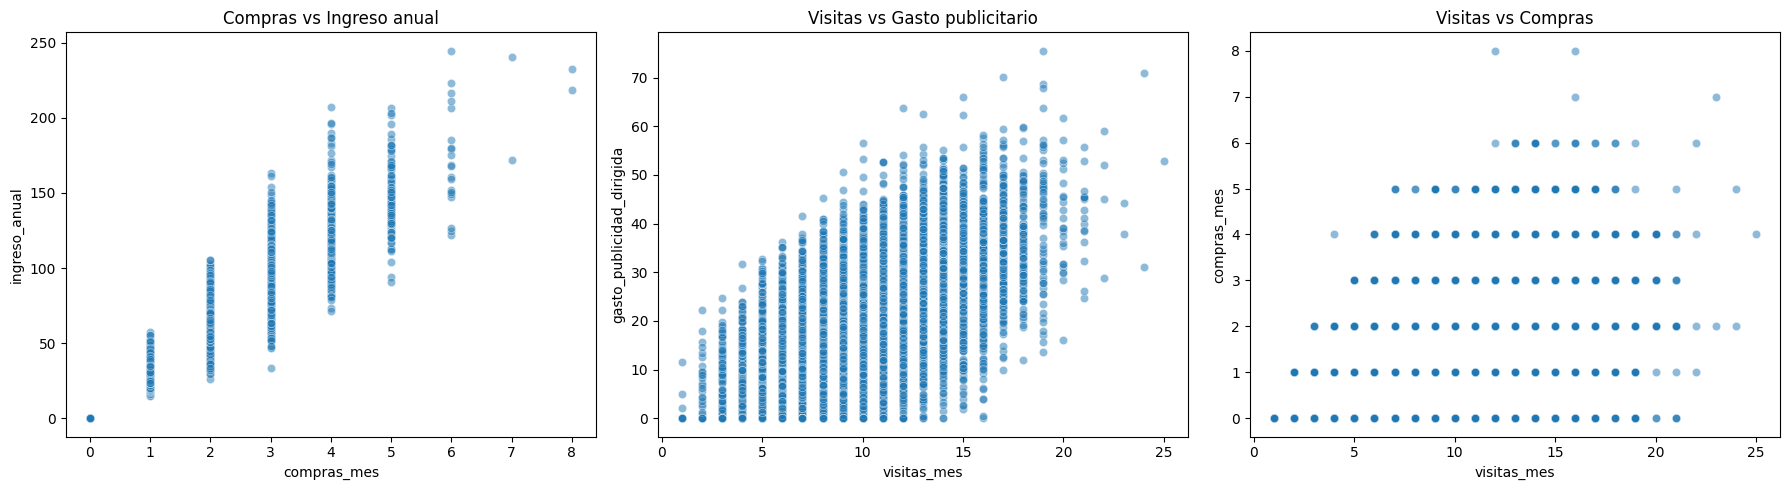

In [ ]:

# Visualizar pares de variables con relaciones moderadas o fuertes

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico 1: Compras vs ingreso anual
sns.scatterplot(
    data=df,
    x='compras_mes',
    y='ingreso_anual',
    ax=axes[0],
    alpha=0.5
)
axes[0].set_title('Compras vs Ingreso anual')

# Gráfico 2: Visitas vs gasto publicitario
sns.scatterplot(
    data=df,
    x='visitas_mes',
    y='gasto_publicidad_dirigida',
    ax=axes[1],
    alpha=0.5
)
axes[1].set_title('Visitas vs Gasto publicitario')

# Gráfico 3: Visitas vs compras
sns.scatterplot(
    data=df,
    x='visitas_mes',
    y='compras_mes',
    ax=axes[2],
    alpha=0.5
)
axes[2].set_title('Visitas vs Compras')

plt.tight_layout()
plt.show()


Observaciones iniciales (Scatterplot)

 **Compras_mes vs ingreso_anual**

Dirección: positiva ascendente, con una tendencia claramente marcada.
Dispersión: relativamente baja en comparación con las otras relaciones, aunque existe variabilidad entre clientes con el mismo número de compras.
Outliers: se identifican algunos clientes con ingresos anuales superiores a 200.

Interpretación: a mayor cantidad de compras mensuales, generalmente se observa un mayor ingreso anual generado. Este comportamiento coincide con la correlación de Pearson de 0.97.

 **Visitas_mes vs gasto_publicidad_dirigida**

Dirección: positiva ascendente.
Dispersión: moderada-alta, debido a la variabilidad del gasto publicitario para un mismo número de visitas.
Outliers: se observan algunos valores de gasto publicitario superiores a 60.

Interpretación: los clientes con mayor número de visitas tienden a presentar mayores niveles de gasto publicitario asignado. La relación coincide con la correlación positiva moderada de 0.58.

 **Visitas_mes vs compras_mes**

Dirección: positiva moderada-débil.
Dispersión: considerable, con diferentes cantidades de compras para un mismo número de visitas.
Outliers: se observan algunos clientes con valores elevados de compras y visitas.

Interpretación: existe una tendencia a realizar más compras cuando aumentan las visitas, aunque la relación no es determinante.

Conclusión general: Los gráficos respaldan visualmente las relaciones identificadas mediante el Heatmap. La asociación más fuerte corresponde a compras_mes e ingreso_anual. Se observan diferencias en la dispersión y algunos valores extremos que deberán considerarse en las siguientes etapas del análisis.

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [ ]:

# Calcular correlación de Pearson entre variables relevantes

print("CORRELACIONES DE PEARSON")

print("\nCompras vs Ingreso anual:")
print(df['compras_mes'].corr(df['ingreso_anual'], method='pearson'))

print("\nVisitas vs Gasto publicitario:")
print(df['visitas_mes'].corr(df['gasto_publicidad_dirigida'], method='pearson'))

print("\nVisitas vs Compras:")
print(df['visitas_mes'].corr(df['compras_mes'], method='pearson'))


CORRELACIONES DE PEARSON

Compras vs Ingreso anual:
0.9671485435708564

Visitas vs Gasto publicitario:
0.5789472719412827

Visitas vs Compras:
0.3538438947198978


In [ ]:

# Calcular correlación de Spearman entre variables relevantes

print("CORRELACIONES DE SPEARMAN")

print("\nCompras vs Ingreso anual:")
print(df['compras_mes'].corr(df['ingreso_anual'], method='spearman'))

print("\nVisitas vs Gasto publicitario:")
print(df['visitas_mes'].corr(df['gasto_publicidad_dirigida'], method='spearman'))

print("\nVisitas vs Compras:")
print(df['visitas_mes'].corr(df['compras_mes'], method='spearman'))


CORRELACIONES DE SPEARMAN

Compras vs Ingreso anual:
0.967482492032673

Visitas vs Gasto publicitario:
0.5592673242622609

Visitas vs Compras:
0.33294292722789276



### Observaciones de correlación

**Compras_mes vs. ingreso_anual**

- **Correlación:** Pearson = 0.967 y Spearman = 0.967.
- Se identifica una asociación positiva muy fuerte. Ambos coeficientes presentan valores prácticamente iguales, lo que indica una relación lineal y monotónica muy marcada. Se recomienda investigar una posible dependencia matemática entre las variables antes de establecer conclusiones de negocio.

**Visitas_mes vs. gasto_publicidad_dirigida**

- **Correlación:** Pearson = 0.579 y Spearman = 0.559.
- Se observa una asociación positiva moderada. La cercanía entre ambos coeficientes sugiere una relación monotónica con un componente lineal importante, aunque existe dispersión en los datos.

**Visitas_mes vs. compras_mes**

- **Correlación:** Pearson = 0.354 y Spearman = 0.333.
- Se presenta una asociación positiva débil a moderada. Esto indica que un mayor número de visitas tiende a relacionarse con un mayor número de compras, aunque la relación no es determinante y existe variabilidad entre los clientes.

**Conclusión general:** Los resultados de Pearson y Spearman son relativamente cercanos en las tres parejas analizadas, lo que respalda la presencia de patrones positivos y monotónicos. La relación más fuerte corresponde a compras_mes e ingreso_anual. Sin embargo, su elevada magnitud requiere investigar una posible dependencia matemática o estructural entre estas variables. Las correlaciones identificadas no demuestran causalidad.

### Punto-biserial

In [ ]:
# Calcular correlación entre variables relevantes

from scipy.stats import pointbiserialr

# Relación entre miembro premium e ingreso anual
corr_premium, p_premium = pointbiserialr(
    df['miembro_premium'],
    df['ingreso_anual']
)

print("Miembro premium vs Ingreso anual:")
print("Correlación:", corr_premium)
print("Valor p:", p_premium)

# Relación entre abandono e ingreso anual
corr_abandono, p_abandono = pointbiserialr(
    df['abandono'],
    df['ingreso_anual']
)

print("\nAbandono vs Ingreso anual:")
print("Correlación:", corr_abandono)
print("Valor p:", p_abandono)

Miembro premium vs Ingreso anual:
Correlación: 0.0930994396198015
Valor p: 3.0943076155242597e-30

Abandono vs Ingreso anual:
Correlación: -0.002823934021617148
Valor p: 0.7294691719078393


### Observaciones Punto-biserial

**miembro_premium vs. ingreso_anual**

- **Relación:** positiva débil, con un coeficiente de correlación de 0.0931.
- El valor p es aproximadamente 3.09 × 10⁻³⁰, inferior a 0.05, por lo que la asociación es estadísticamente significativa.
- Esto indica que los clientes con membresía premium tienden a presentar ingresos anuales ligeramente superiores. Sin embargo, la magnitud de la correlación es pequeña, por lo que su relevancia práctica debe interpretarse con cautela.

**abandono vs. ingreso_anual**

- **Relación:** negativa prácticamente nula, con un coeficiente de correlación de -0.0028.
- El valor p es aproximadamente 0.7295, superior a 0.05, por lo que no se encuentra evidencia estadística suficiente de una asociación lineal significativa.
- Esto indica que, en este conjunto de datos, no se identifica una relación lineal entre el abandono de la plataforma y el ingreso anual generado.

**Conclusión general:** La membresía premium presenta una asociación positiva débil y estadísticamente significativa con el ingreso anual, mientras que el abandono no muestra una asociación significativa. Estos resultados no permiten establecer relaciones causales y deben complementarse con otros análisis para comprender mejor el comportamiento de los clientes.

### V de Cramér

In [ ]:

# Importar función Chi-cuadrado
from scipy.stats import chi2_contingency

In [ ]:

# Función para calcular V de Cramér

def cramers_v(df, col1, col2):
    # Crear tabla de contingencia
    tabla = pd.crosstab(df[col1], df[col2])

    # Calcular Chi-cuadrado
    chi2, _, _, _ = chi2_contingency(tabla)

    # Obtener número total de observaciones
    n = tabla.to_numpy().sum()

    # Calcular V de Cramér
    min_dim = min(tabla.shape[0] - 1, tabla.shape[1] - 1)
    coef_v = np.sqrt(chi2 / (n * min_dim))

    return coef_v

In [ ]:

# Aplicar V de Cramér en variables relevantes

print("REGIÓN VS TIPO DE DISPOSITIVO:")
print(cramers_v(df, 'region', 'tipo_dispositivo'))

print("\nREGIÓN VS MEMBRESÍA PREMIUM:")
print(cramers_v(df, 'region', 'miembro_premium'))

print("\nDISPOSITIVO VS MEMBRESÍA PREMIUM:")
print(cramers_v(df, 'tipo_dispositivo', 'miembro_premium'))

REGIÓN VS TIPO DE DISPOSITIVO:
0.012378338407739397

REGIÓN VS MEMBRESÍA PREMIUM:
0.012574183027958334

DISPOSITIVO VS MEMBRESÍA PREMIUM:
0.01972543445542166



### Observaciones V de Cramér

- **Región vs. tipo_dispositivo:** presenta un coeficiente V de Cramér de 0.0124, lo que indica una asociación prácticamente nula entre la región geográfica y el tipo de dispositivo utilizado por los clientes.

- **Región vs. miembro_premium:** presenta un coeficiente de 0.0126, evidenciando una asociación muy débil entre la región y la pertenencia al programa premium.

- **tipo_dispositivo vs. miembro_premium:** presenta un coeficiente de 0.0197, lo que indica una asociación prácticamente inexistente entre el dispositivo utilizado y la membresía premium.

**Conclusión general:** Las tres asociaciones presentan valores cercanos a cero, por lo que no se identifican relaciones relevantes entre las variables categóricas analizadas. Esto sugiere que la región y el dispositivo utilizado no presentan asociaciones importantes con la membresía premium dentro del conjunto de datos. Los resultados describen asociaciones, pero no permiten establecer causalidad.

## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---

### Hallazgo 1 — La frecuencia de compra presenta una asociación muy fuerte con el ingreso anual

**Evidencia visual:**

El scatterplot de compras_mes vs. ingreso_anual muestra una tendencia positiva claramente definida. Se observa que, a medida que aumenta el número de compras mensuales, también aumentan los ingresos anuales registrados. Los puntos presentan una distribución ascendente, con algunos clientes que alcanzan ingresos superiores a 200.

**Evidencia numérica:**

- Correlación de Pearson: 0.967.
- Correlación de Spearman: 0.967.
- El resultado representa una asociación positiva extraordinariamente fuerte entre ambas variables.

**Interpretación:**

La frecuencia de compra es el comportamiento que presenta la asociación lineal y monotónica más elevada con el ingreso anual generado por los clientes. Esto indica que los clientes que realizan más compras mensuales tienden a registrar mayores ingresos para NovaRetail+.

La similitud entre Pearson y Spearman respalda la consistencia de esta asociación desde ambas perspectivas estadísticas.

**No podemos afirmar:**

No podemos concluir que incrementar artificialmente el número de compras provoque un aumento proporcional del ingreso anual. Tampoco podemos descartar que exista una dependencia matemática entre ambas variables, por ejemplo, que el ingreso anual haya sido construido utilizando la frecuencia de compra como uno de sus componentes. Esta posibilidad debe verificarse antes de establecer conclusiones definitivas.

**Implicación de negocio:**

Se recomienda profundizar en el comportamiento de compra de los clientes, identificar los segmentos con mayor frecuencia de transacciones y evaluar estrategias de fidelización, recompra y retención. Antes de utilizar esta relación para proyectar resultados financieros o diseñar intervenciones comerciales, es necesario validar la metodología de cálculo del ingreso anual y comprobar que ambas métricas sean independientes en su construcción.

### Hallazgo 2 —  La actividad de navegación presenta una asociación positiva con el ingreso anual

**Evidencia visual:**

Los scatterplots de visitas_mes vs. ingreso_anual y visitas_mes vs. compras_mes muestran tendencias ascendentes. Se observa que los clientes con mayor número de visitas tienden a presentar mayores niveles de compras y de ingresos, aunque existe una dispersión considerable entre los registros.

**Evidencia numérica:**

- Pearson entre visitas_mes e ingreso_anual: 0.34.
- Spearman entre visitas_mes e ingreso_anual: aproximadamente 0.34.
- Pearson entre visitas_mes y compras_mes: 0.354.
- Spearman entre visitas_mes y compras_mes: 0.333.

**Interpretación:**

Las visitas mensuales presentan una asociación positiva moderada-débil con el ingreso anual y con la frecuencia de compra. Esto sugiere que una mayor interacción con la plataforma suele coincidir con una mayor actividad comercial. Sin embargo, el número de visitas por sí solo no permite explicar completamente las diferencias en los ingresos generados por los clientes.

**No podemos afirmar:**

No podemos asegurar que aumentar el número de visitas produzca automáticamente un incremento en las compras o en los ingresos. La asociación observada no demuestra causalidad y pueden intervenir otros factores, como la intención de compra, las preferencias individuales, la disponibilidad de productos y las características de cada cliente.

**Implicación de negocio:**

Se recomienda analizar el recorrido de los usuarios dentro de la plataforma, identificar los puntos en los que las visitas se convierten en compras y evaluar estrategias de optimización de conversión. También sería conveniente segmentar a los clientes según su nivel de interacción para identificar oportunidades de mejora en la experiencia de navegación y en la conversión comercial.

### Hallazgo 3 — Las variables de segmentación presentan asociaciones débiles con el ingreso y entre sí

**Evidencia visual:**

El Heatmap muestra asociaciones cercanas a cero entre ingreso_anual y variables como edad, nivel_ingreso, satisfacción y membresía premium. Asimismo, el análisis de variables categóricas no evidencia asociaciones relevantes entre región, tipo de dispositivo y membresía premium.

**Evidencia numérica:**

- Punto-biserial entre miembro_premium e ingreso_anual: 0.0931 (p aproximadamente 3.09 × 10⁻³⁰).
- Punto-biserial entre abandono e ingreso_anual: -0.0028 (p aproximadamente 0.7295).
- V de Cramér entre región y tipo de dispositivo: 0.0124.
- V de Cramér entre región y membresía premium: 0.0126.
- V de Cramér entre dispositivo y membresía premium: 0.0197.

**Interpretación:**

La membresía premium presenta una asociación positiva, pero débil, con el ingreso anual. Aunque esta asociación es estadísticamente significativa, su magnitud es pequeña. Por otra parte, el abandono no presenta una asociación lineal estadísticamente significativa con el ingreso anual.

Los valores de V de Cramér indican asociaciones prácticamente nulas entre las variables categóricas analizadas. En consecuencia, la región y el dispositivo utilizado no muestran asociaciones relevantes con la pertenencia al programa premium.

**No podemos afirmar:**

No podemos concluir que la membresía premium incremente los ingresos ni que el abandono sea irrelevante para la sostenibilidad del negocio. Tampoco podemos afirmar que las características geográficas o tecnológicas carezcan de importancia para otros indicadores de comportamiento y experiencia del cliente.

**Implicación de negocio:**

Se recomienda revisar la propuesta de valor del programa premium, evaluar sus beneficios y estudiar las diferencias de comportamiento entre suscriptores y no suscriptores. Asimismo, conviene analizar el abandono mediante indicadores adicionales, como antigüedad del cliente, frecuencia de compra, recurrencia y tiempo desde la última interacción. Las estrategias comerciales deberían apoyarse en patrones de comportamiento y valor económico, evitando segmentaciones basadas exclusivamente en región o dispositivo.

## Sección 6 - Limitaciones y próximos pasos


### **Limitaciones**

El presente análisis es de carácter exploratorio y correlacional. Sus resultados permiten identificar asociaciones entre variables relacionadas con el comportamiento de los clientes y los ingresos generados, pero deben interpretarse considerando las siguientes limitaciones:

- **Correlación no implica causalidad:** las asociaciones identificadas no demuestran que una variable provoque cambios en otra. Por ejemplo, la relación entre compras mensuales e ingreso anual no permite afirmar por sí sola que incrementar las compras produzca un aumento proporcional de los ingresos.
- **Posible dependencia matemática entre variables:** se identificó una correlación muy elevada entre compras_mes e ingreso_anual (Pearson = 0.967). Es necesario verificar cómo se construyó la variable ingreso_anual, debido a que podría incorporar la frecuencia de compra en su cálculo y generar una asociación estructural entre ambas variables.
- **Alcance temporal de la información:** el conjunto de datos corresponde al periodo 2024. Por tanto, los resultados representan los patrones observados en ese conjunto de información y no necesariamente reflejan el comportamiento de los clientes en periodos posteriores.
- **Variables no incluidas:** el análisis contempla características demográficas, económicas y de comportamiento, pero pueden existir otros factores relevantes que no están representados, como descuentos, precios, categorías de productos, antigüedad del cliente, campañas comerciales, devoluciones y estacionalidad.
- **Relaciones no lineales:** Pearson identifica relaciones lineales y Spearman relaciones monotónicas. Por lo tanto, pueden existir patrones más complejos que no sean capturados completamente mediante estos coeficientes.
- **Distribución y valores extremos:** se identificaron diferencias importantes en los rangos de algunas variables y posibles valores extremos. Estos pueden influir en los resultados de correlación y requieren análisis complementarios.
- **Significancia estadística y relevancia práctica:** aunque la membresía premium presenta una asociación estadísticamente significativa con el ingreso anual (p < 0.05), la magnitud de la relación es débil (r = 0.093). Por ello, la significancia estadística no debe confundirse con un impacto comercial importante.
- **Alcance de las asociaciones categóricas:** los coeficientes V de Cramér muestran asociaciones muy débiles entre las parejas analizadas. Sin embargo, no se calcularon valores p para estas asociaciones, por lo que no se realizaron pruebas formales de significancia estadística para ellas.

## Próximos pasos

Con el propósito de profundizar en los hallazgos y generar recomendaciones que aporten valor a las estrategias de crecimiento y retención de NovaRetail+, se proponen las siguientes acciones:

### Paso 1. Profundizar en la segmentación de clientes

- Clasificar a los clientes según su frecuencia de compra, nivel de interacción e ingreso anual.
- Comparar el comportamiento de clientes premium y no premium.
- Identificar segmentos de clientes de alto valor, clientes recurrentes y clientes con baja actividad comercial.

### Paso 2. Validar los factores asociados al ingreso anual

- Revisar la metodología de cálculo de la variable ingreso_anual para determinar si incorpora directamente el número de compras.
- Analizar otras variables económicas y de comportamiento que puedan aportar información independiente sobre el valor generado por los clientes.
- Evaluar la relación entre visitas, gasto publicitario, satisfacción y compras mediante análisis complementarios.

### Paso 3. Desarrollar análisis predictivos y experimentales

- Construir modelos de regresión para explorar qué variables aportan mayor información para estimar el ingreso anual.
- Incorporar información histórica para analizar cambios en el comportamiento y la retención de clientes.
- Diseñar pruebas A/B para evaluar estrategias de fidelización, incentivos de recompra y optimización de la conversión.
- Medir los resultados mediante indicadores como tasa de conversión, frecuencia de compra, ingreso promedio por cliente y tasa de retención.

## Conclusión de la sección

Los resultados del análisis permiten identificar la frecuencia de compra como la variable con mayor asociación con el ingreso anual, seguida de la actividad de navegación. También se identificaron asociaciones débiles entre la membresía premium y los ingresos, así como asociaciones prácticamente nulas entre las variables categóricas evaluadas.

Estos hallazgos constituyen un punto de partida para profundizar en el conocimiento del comportamiento de los clientes de NovaRetail+. Se recomienda complementar el análisis correlacional con validaciones metodológicas, segmentación, modelos predictivos y experimentación, con el fin de transformar la evidencia disponible en decisiones estratégicas para el crecimiento, la conversión y la retención de clientes.


In [ ]:
Nicole A. Lozano Lurduy
Data Analyst.